In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from itertools import product

import midplane_model as mm   # midplane_model.py must be in this notebook's folder

# --- segment helpers (copied from your coords.py) ---
def wrap_to_2pi(a):
    return np.mod(a, 2 * np.pi)

def between_ccw(x, a, b):
    da = (b - a) % (2 * np.pi)
    dx = (x - a) % (2 * np.pi)
    return dx < da

def build_segment_setup(phi_star, phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=11):
    ph = wrap_to_2pi(phi_star)
    phi0 = wrap_to_2pi(phi0)
    hw = np.deg2rad(crowd_halfwidth_deg)
    a, b = wrap_to_2pi(phi0 - hw), wrap_to_2pi(phi0 + hw)
    span = (b - a) % (2 * np.pi)
    crowd_bounds = wrap_to_2pi(a + np.linspace(0, span, n_crowd + 1))
    segm = {i + 1: between_ccw(ph, crowd_bounds[i], crowd_bounds[i + 1]) for i in range(n_crowd)}
    segm[n_crowd + 1] = ~between_ccw(ph, a, b)
    return segm, crowd_bounds, (a, b), {"n_crowd": n_crowd, "seg_rest_id": n_crowd + 1}

# --- settings matched to your APOGEE pipeline ---
z_edges          = np.linspace(-3.0, 3.0, 181)
R_edges          = np.arange(0.5, 15.5 + 0.5, 0.5)
minN_seg_total   = 15
min_bin_count    = 5
min_bins_for_fit = 8
z_fit_min, z_fit_max = -1.5, 1.5
zlim             = 0.6
R_centers        = 0.5 * (R_edges[:-1] + R_edges[1:])
mm.Z_BINS_FIT    = z_edges
OFE_ERR          = 1e-4
phi0             = np.pi

# --- load the new CSVs (edit the filenames if you changed them) ---
files = {"merger": "2sim_disc_merger.csv", "host": "2sim_disc_host.csv"}

prepared = {}
for name, fn in files.items():
    df = pd.read_csv(fn)
    print(name, "columns:", list(df.columns))

    keep = np.isfinite(df[["R", "z", "phi", "ofe"]]).all(axis=1) & (df["R"] < 16.0)
    df = df[keep]

    R, z, phi = df["R"].to_numpy(), df["z"].to_numpy(), df["phi"].to_numpy()
    tracer = df["ofe"].to_numpy()
    tracer_err = np.full_like(tracer, OFE_ERR, dtype=float)

    segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(phi, phi0=phi0)
    SEG = list(range(1, seg_diag["n_crowd"] + 1))

    prepared[name] = dict(R=R, z=z, phi=phi, tracer=tracer, tracer_err=tracer_err,
                          age=df["age"].to_numpy() if "age" in df else None,
                          segm=segm, crowd_bounds=crowd_bounds, SEG_PLOT_heat=SEG)
    print(f"{name}: {len(R)} stars, {sum(segm[i].sum() for i in SEG)} in the wedge")

merger columns: ['R', 'phi', 'z', 'tform', 'age', 'feh', 'ofe']
merger: 39919181 stars, 10012083 in the wedge
host columns: ['R', 'phi', 'z', 'tform', 'age', 'feh', 'ofe']
host: 49289381 stars, 12666588 in the wedge


In [2]:
for name, d in prepared.items():
    age = d["age"]
    fin = np.isfinite(age)
    print(f"{name}: {fin.sum()} finite ages, {(~fin).sum()} NaN/inf")
    print(f"  min={age[fin].min():.3f}  max={age[fin].max():.3f}  "
          f"median={np.median(age[fin]):.3f}")
    print("  percentiles (1, 16, 50, 84, 99):",
          np.round(np.percentile(age[fin], [1, 16, 50, 84, 99]), 3))
    print(f"  negative ages: {(age[fin] < 0).sum()}")

merger: 39919181 finite ages, 0 NaN/inf
  min=-0.000  max=10.839  median=8.420
  percentiles (1, 16, 50, 84, 99): [ 0.429  5.245  8.42  10.041 10.792]
  negative ages: 411
host: 49289381 finite ages, 0 NaN/inf
  min=-0.000  max=14.419  median=7.439
  percentiles (1, 16, 50, 84, 99): [ 0.278  3.576  7.439 10.607 14.192]
  negative ages: 1096


In [4]:
import os

FORCE_RERUN = False
z0_summary = {}

for name, d in prepared.items():
    path = f"2sim_grid_fit_z0_{name}.pkl"
    if os.path.exists(path) and not FORCE_RERUN:
        saved = pickle.load(open(path, "rb"))
        z0_summary[name] = dict(z0_med=saved["z0_med"], z0_std=saved["z0_std"])
        print(f"{name}: loaded {path}")
    else:
        seg_masks_fit = {i: d["segm"][i] for i in d["SEG_PLOT_heat"]}
        per_cell = mm.run_grid_fit(
            d["R"], d["z"], d["tracer"], d["tracer_err"], seg_masks_fit, R_edges,
            model_fn=mm.model_z0, label=f"{name}_z0", results_path=path,
            minN_total=minN_seg_total, min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit, z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )
        z0_med, z0_std, _, _ = mm.summarize_grid_fit(
            per_cell, n_R=len(R_edges) - 1, n_seg=len(seg_masks_fit))
        z0_summary[name] = dict(z0_med=z0_med, z0_std=z0_std)

[merger_z0] grid fit:   0%|                             | 0/330 [00:00<?, ?it/s]/Users/emmatasso/outerdisk/midplane_model.py:194: RuntimeWarning: invalid value encountered in divide
  mean_tracer = stat1.statistic / stat2.statistic
/Users/emmatasso/outerdisk/midplane_model.py:195: RuntimeWarning: divide by zero encountered in divide
  mean_tracer_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter ** 2)
/Users/emmatasso/outerdisk/midplane_model.py:206: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
[merger_z0] grid fit: 100%|███████████████████| 330/330 [25:26<00:00,  4.63s/it]


[merger_z0] grid fits complete: 330/330
[merger_z0] saved to 2sim_grid_fit_z0_merger.pkl


[host_z0] grid fit: 100%|█████████████████████| 330/330 [25:26<00:00,  4.63s/it]


[host_z0] grid fits complete: 330/330
[host_z0] saved to 2sim_grid_fit_z0_host.pkl


summarizing grid fit: 100%|███████████████████| 330/330 [03:32<00:00,  1.55it/s]


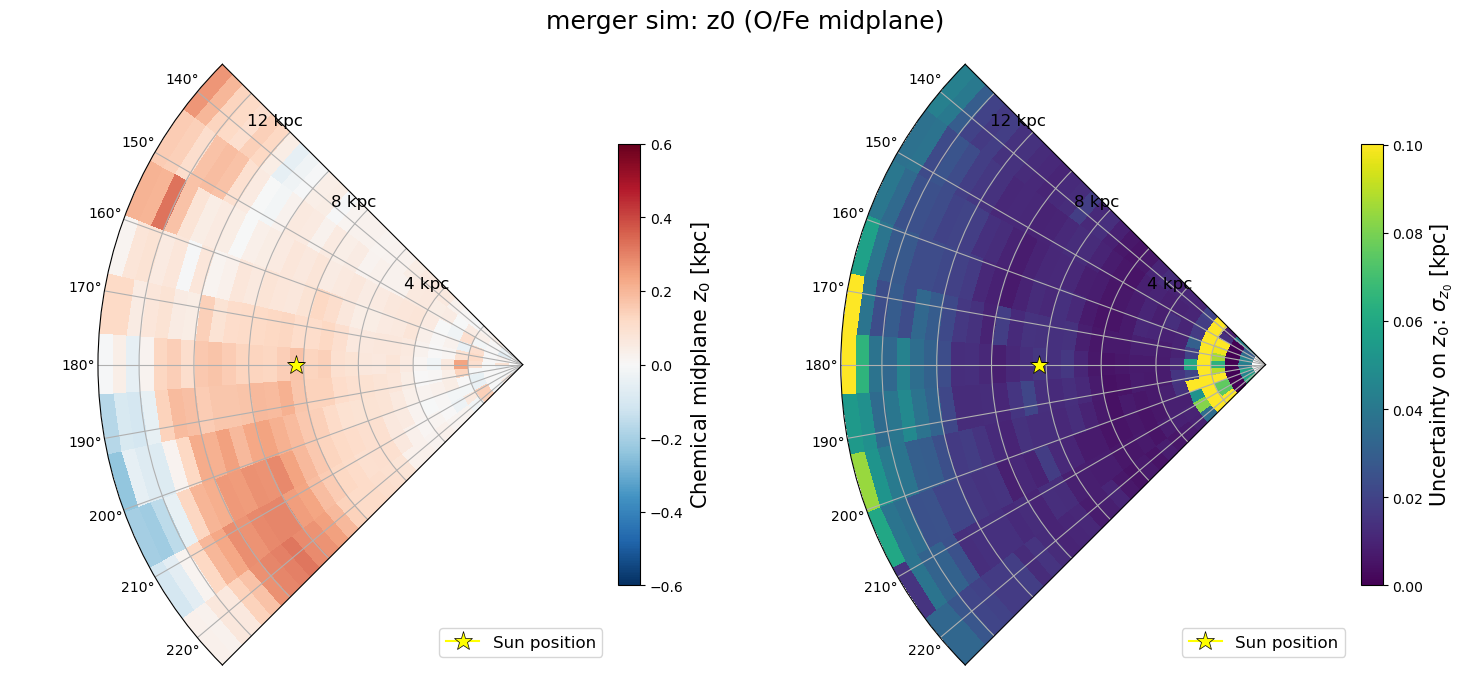

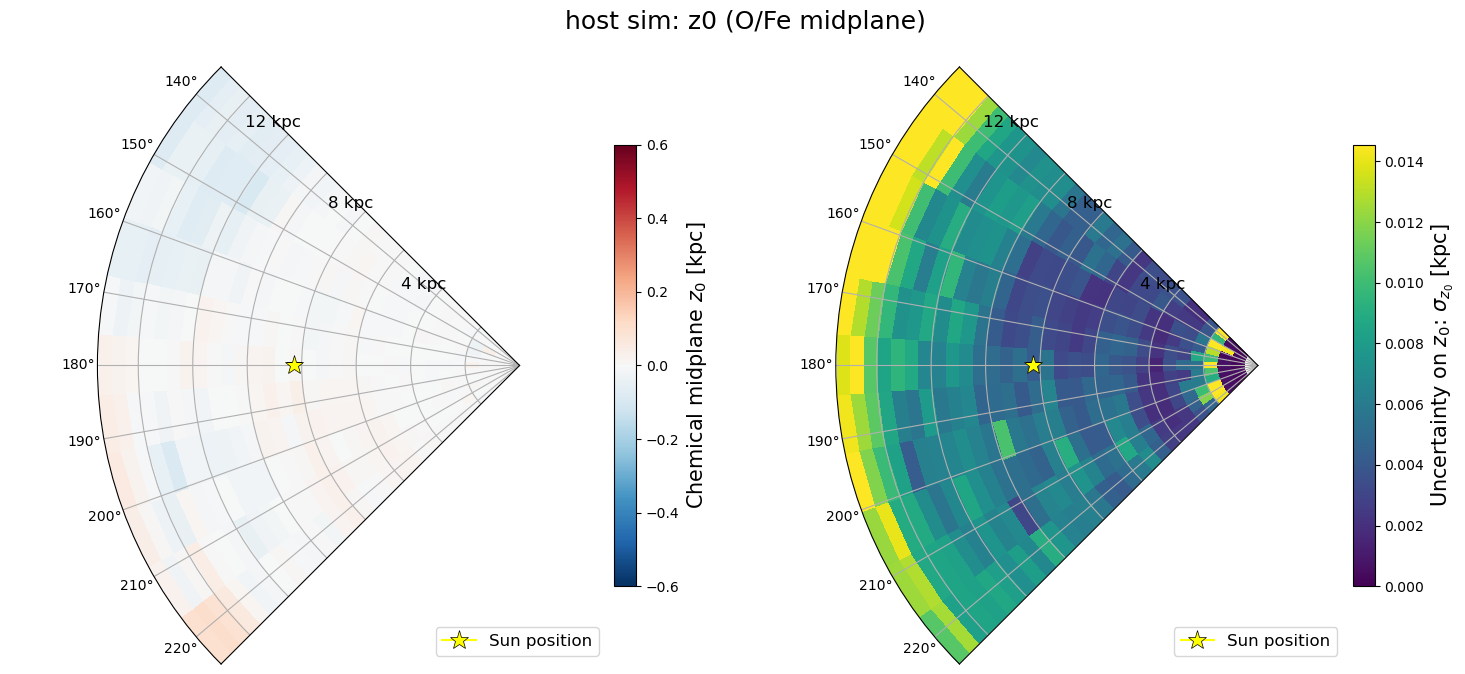

In [5]:
def plot_z0_heatmap_sim(z0_med_bin, z0_std_bin, label, crowd_bounds, n_seg):
    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi
    assert len(theta_edges) - 1 == n_seg

    T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
    Zmed = np.ma.masked_invalid(z0_med_bin)
    Zstd = np.ma.masked_invalid(z0_std_bin)
    std_max = (float(np.nanpercentile(z0_std_bin[np.isfinite(z0_std_bin)], 95))
               if np.isfinite(z0_std_bin).any() else 1.0)
    tmin, tmax = theta_edges[0], theta_edges[-1]
    theta_sun, R_sun = np.radians(180), 8.275

    fig = plt.figure(figsize=(15, 7))
    fig.suptitle(label, fontsize=18)
    for k, (arr, cmap, vmin, vmax, lab) in enumerate([
        (Zmed, "RdBu_r", -zlim, zlim, r"Chemical midplane $z_0$ [kpc]"),
        (Zstd, "viridis", 0.0, std_max, r"Uncertainty on $z_0$: $\sigma_{z_0}$ [kpc]"),
    ], start=1):
        ax = plt.subplot(1, 2, k, projection="polar")
        pcm = ax.pcolormesh(T_mesh, R_mesh, arr, cmap=cmap, vmin=vmin, vmax=vmax, shading="flat")
        fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(lab, fontsize=15)
        ax.set_theta_zero_location("E"); ax.set_theta_direction(1)
        ax.set_rmax(R_edges[-1])
        ax.set_thetamin(np.degrees(tmin)); ax.set_thetamax(np.degrees(tmax))
        ax.set_yticklabels([])
        for r in R_edges[R_edges % 4 == 0]:
            ax.text(tmin - np.radians(3), r, f"{r:.0f} kpc", fontsize=12, ha="right", va="center")
        ax.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
                markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun position")
        ax.legend(loc="lower right", fontsize=12)
    plt.tight_layout()
    plt.show()

for name, d in prepared.items():
    plot_z0_heatmap_sim(z0_summary[name]["z0_med"], z0_summary[name]["z0_std"],
                        f"{name} sim: z0 (O/Fe midplane)", d["crowd_bounds"], len(d["SEG_PLOT_heat"]))

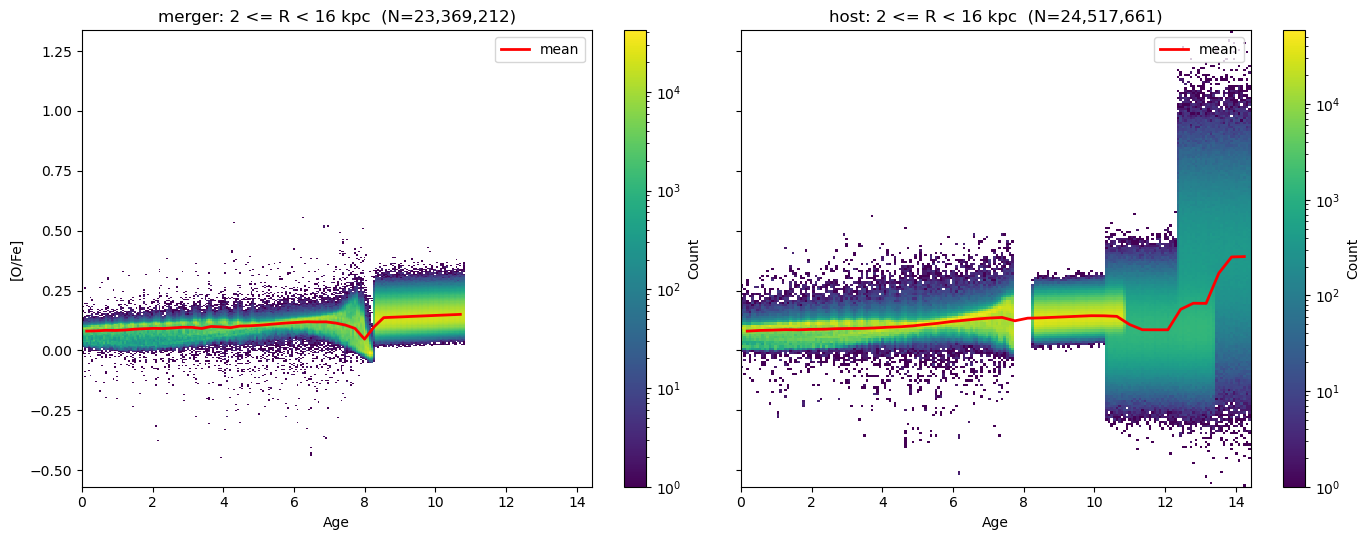

In [7]:
from matplotlib.colors import LogNorm

def plot_ofe_vs_age(R_min=6.0, R_max=16.0, wedge_only=False,
                    age_bins=200, ofe_bins=200, ofe_range=None, age_range=None):
    fig, axes = plt.subplots(1, len(prepared), figsize=(7 * len(prepared), 5.5),
                             sharex=True, sharey=True, squeeze=False)

    for ax, (name, d) in zip(axes[0], prepared.items()):
        m = (d["R"] >= R_min) & (d["R"] < R_max)
        if wedge_only:
            in_wedge = np.zeros_like(m)
            for i in d["SEG_PLOT_heat"]:
                in_wedge |= d["segm"][i]
            m &= in_wedge

        age, ofe = d["age"][m], d["tracer"][m]
        ok = np.isfinite(age) & np.isfinite(ofe)
        age, ofe = age[ok], ofe[ok]

        h = ax.hist2d(age, ofe, bins=[age_bins, ofe_bins],
                      range=None if (age_range is None and ofe_range is None)
                      else [age_range or [age.min(), age.max()],
                            ofe_range or [ofe.min(), ofe.max()]],
                      norm=LogNorm(), cmap="viridis")
        fig.colorbar(h[3], ax=ax, label="Count")

        # mean [O/Fe] in age bins
        edges = np.linspace(age.min(), age.max(), 41)
        idx = np.digitize(age, edges) - 1
        centers = 0.5 * (edges[:-1] + edges[1:])
        mean = np.array([ofe[idx == k].mean() if (idx == k).sum() > 20 else np.nan
                         for k in range(len(centers))])
        ax.plot(centers, mean, color="red", lw=2, label="mean")

        ax.set_xlabel("Age")
        ax.set_title(f"{name}: {R_min:g} <= R < {R_max:g} kpc  (N={len(age):,})")
        ax.legend()
    axes[0][0].set_ylabel("[O/Fe]")
    plt.tight_layout()
    plt.show()

# change these and rerun
plot_ofe_vs_age(R_min=2.0, R_max=16.0)

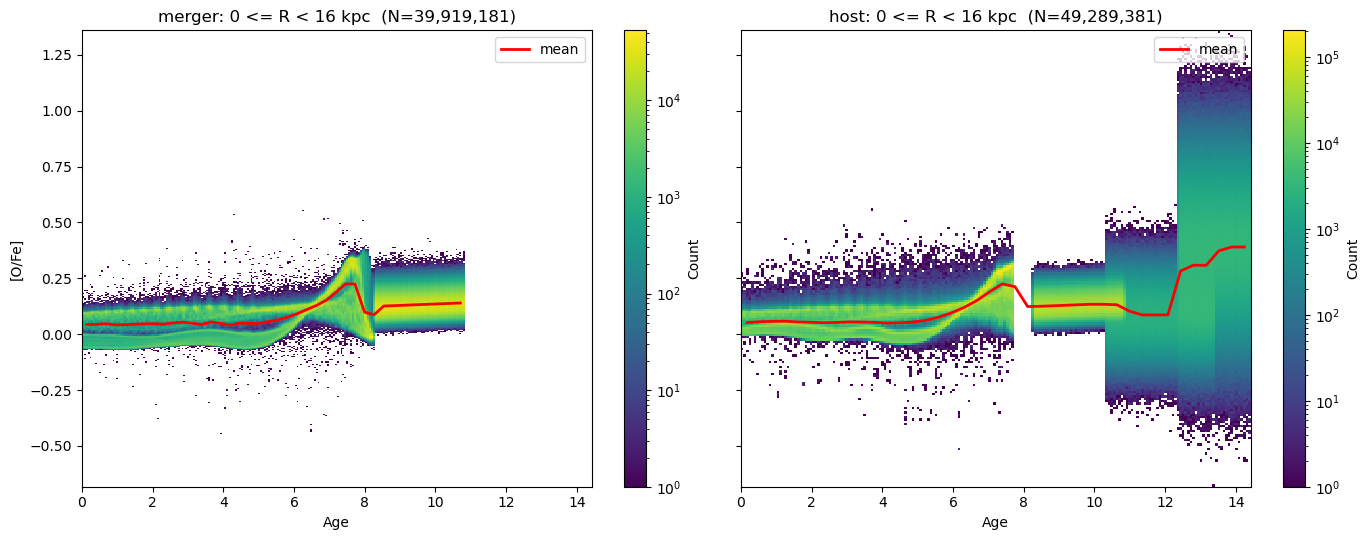

In [8]:
plot_ofe_vs_age(R_min=0.0, R_max=16.0)

In [9]:
def geometric_midplane(d, zlo=z_fit_min, zhi=z_fit_max):
    n_R, n_seg = len(R_edges) - 1, len(d["SEG_PLOT_heat"])

    seg_idx = np.full(len(d["R"]), -1, dtype=np.int16)
    for j, sid in enumerate(d["SEG_PLOT_heat"]):
        seg_idx[d["segm"][sid]] = j
    iR = np.digitize(d["R"], R_edges) - 1

    ok = ((seg_idx >= 0) & (iR >= 0) & (iR < n_R) & np.isfinite(d["z"])
          & (d["z"] >= zlo) & (d["z"] <= zhi))
    cell = iR[ok] * n_seg + seg_idx[ok]
    zz = d["z"][ok]
    order = np.argsort(cell, kind="stable")
    cell, zz = cell[order], zz[order]

    ids, start, counts = np.unique(cell, return_index=True, return_counts=True)
    med = np.full(n_R * n_seg, np.nan)
    nst = np.zeros(n_R * n_seg, dtype=int)
    for cid, s0, c in zip(ids, start, counts):
        if c >= minN_seg_total:
            med[cid] = np.median(zz[s0:s0 + c])
            nst[cid] = c
    return med.reshape(n_R, n_seg), nst.reshape(n_R, n_seg)

geo = {name: geometric_midplane(d) for name, d in prepared.items()}

[merger_chem_z0] fitting radial bins:   0%|              | 0/30 [00:00<?, ?it/s]/Users/emmatasso/outerdisk/midplane_model.py:194: RuntimeWarning: invalid value encountered in divide
  mean_tracer = stat1.statistic / stat2.statistic
/Users/emmatasso/outerdisk/midplane_model.py:195: RuntimeWarning: divide by zero encountered in divide
  mean_tracer_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter ** 2)
/Users/emmatasso/outerdisk/midplane_model.py:206: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
[merger_chem_z0] fitting radial bins:   3%|▏     | 1/30 [00:19<09:39, 19.98s/it]

[merger_chem_z0] R=[0.5,1.0]: fit ok, n_stars=6734301


[merger_chem_z0] fitting radial bins:   7%|▍     | 2/30 [00:40<09:20, 20.03s/it]

[merger_chem_z0] R=[1.0,1.5]: fit ok, n_stars=2568637


[merger_chem_z0] fitting radial bins:  10%|▌     | 3/30 [00:57<08:25, 18.74s/it]

...

[host_chem_z0] R=[14.0,14.5]: fit ok, n_stars=807162


[host_chem_z0] fitting radial bins:  97%|██████▊| 29/30 [07:33<00:19, 19.50s/it]

[host_chem_z0] R=[14.5,15.0]: fit ok, n_stars=764902


[host_chem_z0] fitting radial bins: 100%|███████| 30/30 [07:59<00:00, 15.99s/it]

[host_chem_z0] R=[15.0,15.5]: fit ok, n_stars=704670
[host_chem_z0] fits complete: 30/30


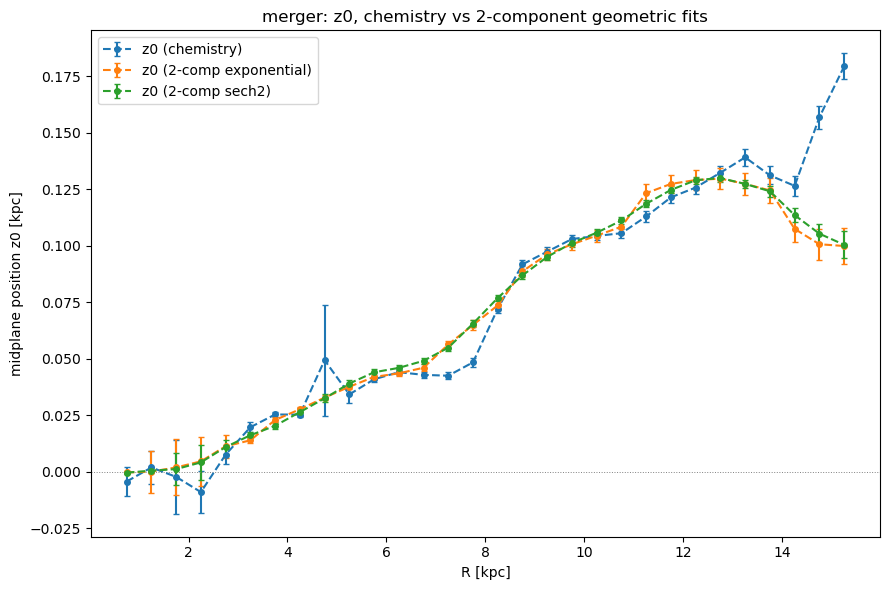

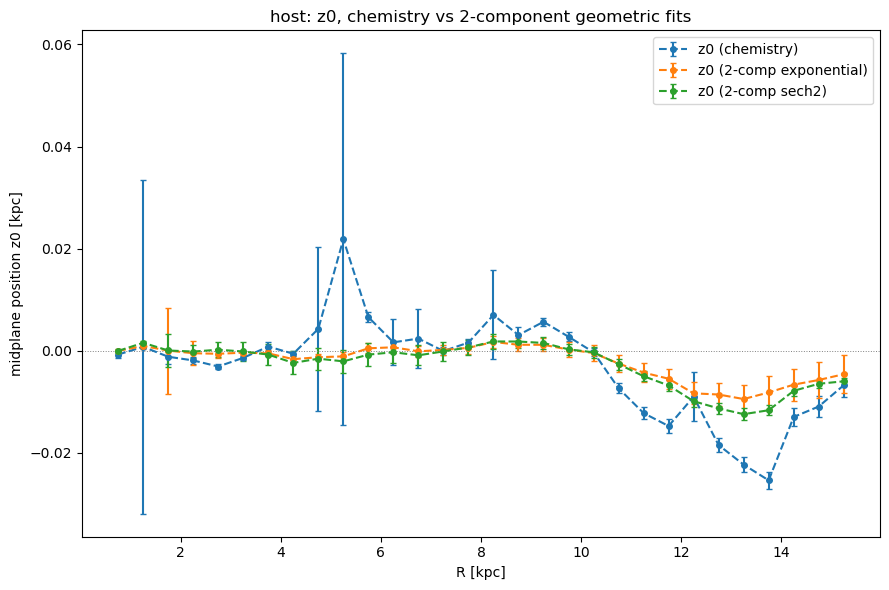

In [11]:
from scipy.optimize import curve_fit

wedge_only = False   # True = use only the +/-45 deg wedge (matches APOGEE footprint)

# ---------- geometric density fits ----------
def two_sech2(z, A1, A2, h1, h2, z0):
    return A1 / np.cosh((z - z0) / h1) ** 2 + A2 / np.cosh((z - z0) / h2) ** 2

def two_exp(z, A1, A2, h1, h2, z0):
    return A1 * np.exp(-np.abs(z - z0) / h1) + A2 * np.exp(-np.abs(z - z0) / h2)

z_cent = 0.5 * (z_edges[:-1] + z_edges[1:])

def fit_density_z0(z_in_bin, model):
    counts, _ = np.histogram(z_in_bin, bins=z_edges)
    if counts.sum() < 200:
        return np.nan, np.nan
    y = counts / counts.max()
    sig = np.sqrt(np.maximum(counts, 1)) / counts.max()
    z_init = np.median(z_in_bin[np.abs(z_in_bin) < 0.5]) if np.any(np.abs(z_in_bin) < 0.5) else 0.0
    p0 = [0.7, 0.3, 0.2, 0.8, z_init]
    lo = [0, 0, 0.02, 0.02, -1.0]
    hi = [2, 2, 2.0, 5.0, 1.0]
    try:
        popt, pcov = curve_fit(model, z_cent, y, p0=p0, sigma=sig, bounds=(lo, hi), maxfev=20000)
        return popt[4], np.sqrt(pcov[4, 4])
    except Exception:
        return np.nan, np.nan

# ---------- run per sim ----------
radial = {}
for name, d in prepared.items():
    m = np.isfinite(d["R"]) & np.isfinite(d["z"])
    if wedge_only:
        in_w = np.zeros_like(m)
        for i in d["SEG_PLOT_heat"]:
            in_w |= d["segm"][i]
        m &= in_w
    R_s, z_s, t_s, e_s = d["R"][m], d["z"][m], d["tracer"][m], d["tracer_err"][m]

    # chemistry: radial-only model_z0 fit in the same R bins
    per_R = mm.fit_flare_bin(
        R_s, z_s, t_s, e_s, R_centers, model_fn=mm.model_z0, R_width=R_edges[1] - R_edges[0],
        label=f"{name}_chem_z0", results_path=None,
        minN_total=minN_seg_total, min_bin_count=min_bin_count,
        min_bins_for_fit=min_bins_for_fit, z_fit_min=z_fit_min, z_fit_max=z_fit_max)
    chem = {i: (0.5 * (c["Rlo"] + c["Rhi"]), np.median(c["samples"]["z0"]), np.std(c["samples"]["z0"]))
            for i, c in per_R.items()}

    # geometry: density fits in each R bin (|z| < 3 kpc from z_edges)
    geo = {"exp": [], "sech2": []}
    Rmid = []
    for k in range(len(R_edges) - 1):
        sel = (R_s >= R_edges[k]) & (R_s < R_edges[k + 1])
        zb = z_s[sel]
        zb = zb[(zb >= z_edges[0]) & (zb <= z_edges[-1])]
        Rmid.append(0.5 * (R_edges[k] + R_edges[k + 1]))
        geo["exp"].append(fit_density_z0(zb, two_exp))
        geo["sech2"].append(fit_density_z0(zb, two_sech2))
    radial[name] = dict(chem=chem, geo=geo, Rmid=np.array(Rmid))

# ---------- plot ----------
for name, r in radial.items():
    plt.figure(figsize=(9, 6))
    Rc = np.array([v[0] for v in r["chem"].values()])
    zc = np.array([v[1] for v in r["chem"].values()])
    ec = np.array([v[2] for v in r["chem"].values()])
    plt.errorbar(Rc, zc, yerr=ec, fmt="o--", ms=4, capsize=2, color="C0", label="z0 (chemistry)")

    for key, color, lab in [("exp", "C1", "z0 (2-comp exponential)"),
                            ("sech2", "C2", "z0 (2-comp sech2)")]:
        arr = np.array(r["geo"][key])
        plt.errorbar(r["Rmid"], arr[:, 0], yerr=arr[:, 1], fmt="o--", ms=4, capsize=2,
                     color=color, label=lab)

    plt.axhline(0, color="gray", lw=0.7, ls=":")
    plt.xlabel("R [kpc]")
    plt.ylabel("midplane position z0 [kpc]")
    plt.title(f"{name}: z0, chemistry vs 2-component geometric fits")
    plt.legend()
    plt.tight_layout()
    plt.show()

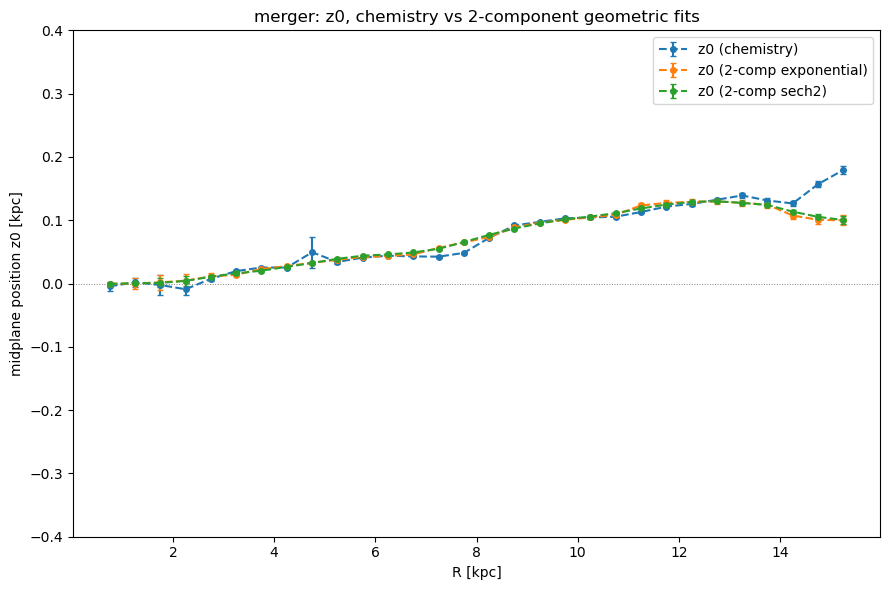

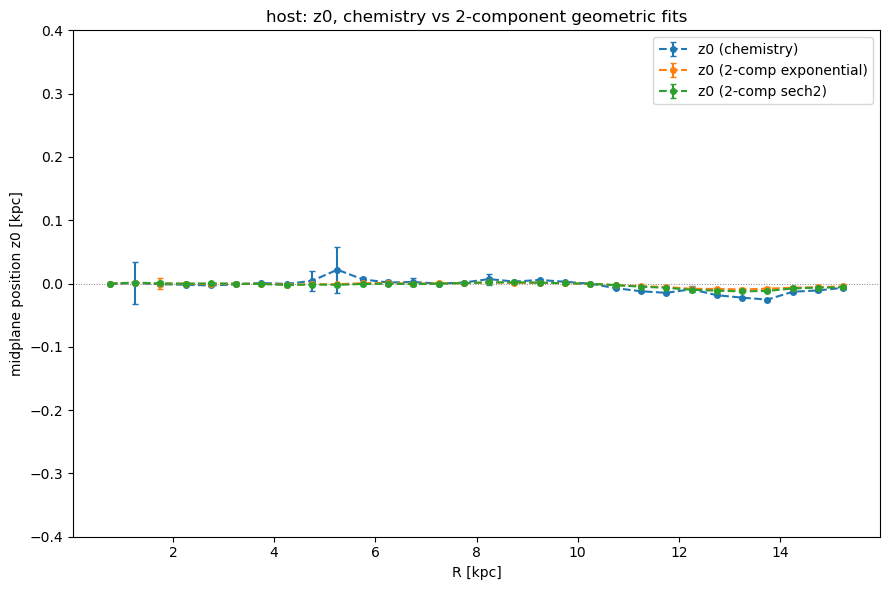

In [15]:
for name, r in radial.items():
    plt.figure(figsize=(9, 6))
    Rc = np.array([v[0] for v in r["chem"].values()])
    zc = np.array([v[1] for v in r["chem"].values()])
    ec = np.array([v[2] for v in r["chem"].values()])
    plt.errorbar(Rc, zc, yerr=ec, fmt="o--", ms=4, capsize=2, color="C0", label="z0 (chemistry)")

    for key, color, lab in [("exp", "C1", "z0 (2-comp exponential)"),
                            ("sech2", "C2", "z0 (2-comp sech2)")]:
        arr = np.array(r["geo"][key])
        plt.errorbar(r["Rmid"], arr[:, 0], yerr=arr[:, 1], fmt="o--", ms=4, capsize=2,
                     color=color, label=lab)

    plt.axhline(0, color="gray", lw=0.7, ls=":")
    plt.xlabel("R [kpc]")
    plt.ylabel("midplane position z0 [kpc]")
    plt.title(f"{name}: z0, chemistry vs 2-component geometric fits")
    plt.legend()
    plt.ylim(-.4,.4)
    plt.tight_layout()
    plt.show()

host: 330 cells with a mean-z value
merger: 330 cells with a mean-z value


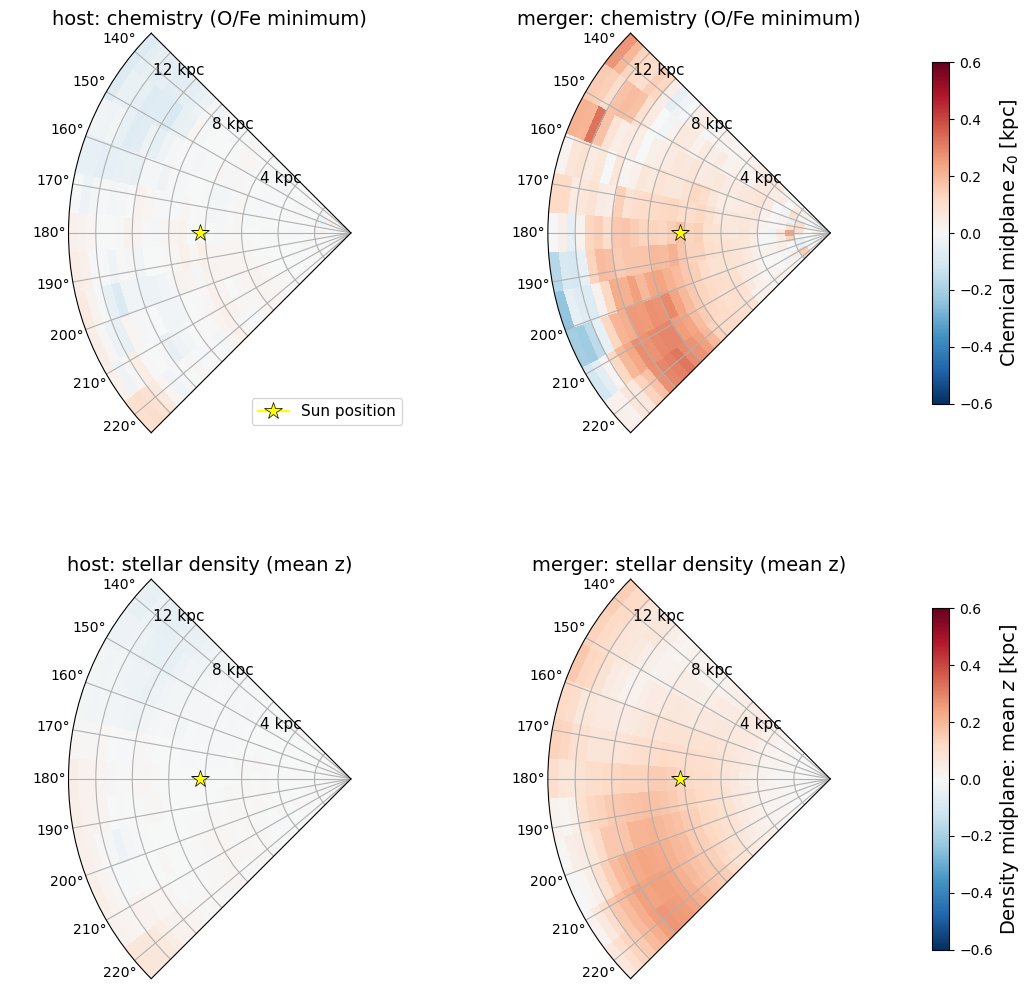

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Density midplane: mean z of the stars in each (R bin, segment) cell
# Same window (|z| < 1.5) and minimum star count as the chemistry fits.
# ---------------------------------------------------------------------------
def mean_z_grid(d, z_min=z_fit_min, z_max=z_fit_max, minN=minN_seg_total):
    n_R, n_seg = len(R_edges) - 1, len(d["SEG_PLOT_heat"])
    iR = np.digitize(d["R"], R_edges) - 1
    in_window = (iR >= 0) & (iR < n_R) & (d["z"] >= z_min) & (d["z"] <= z_max)

    grid = np.full((n_R, n_seg), np.nan)
    for j, seg in enumerate(d["SEG_PLOT_heat"]):
        m = in_window & d["segm"][seg]
        counts = np.bincount(iR[m], minlength=n_R)
        sums = np.bincount(iR[m], weights=d["z"][m], minlength=n_R)
        with np.errstate(invalid="ignore", divide="ignore"):
            grid[:, j] = np.where(counts >= minN, sums / counts, np.nan)
    return grid

zmean_summary = {name: mean_z_grid(prepared[name]) for name in ["host", "merger"]}
for name, g in zmean_summary.items():
    print(f"{name}: {int(np.isfinite(g).sum())} cells with a mean-z value")

# ---------------------------------------------------------------------------
# 2x2 figure
# ---------------------------------------------------------------------------
def theta_edges_from(crowd_bounds, n_seg):
    te = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(te)):
        while te[i] <= te[i - 1]:
            te[i] += 2 * np.pi
    assert len(te) - 1 == n_seg
    return te

d0 = prepared["host"]
theta_edges = theta_edges_from(d0["crowd_bounds"], len(d0["SEG_PLOT_heat"]))
T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
tmin, tmax = theta_edges[0], theta_edges[-1]
theta_sun, R_sun = np.radians(180), 8.275

rows = [
    ("chemistry (O/Fe minimum)", {n: z0_summary[n]["z0_med"] for n in ["host", "merger"]},
     r"Chemical midplane $z_0$ [kpc]"),
    ("stellar density (mean z)", zmean_summary,
     r"Density midplane: mean $z$ [kpc]"),
]
cols = ["host", "merger"]

fig, axes = plt.subplots(2, 2, subplot_kw={"projection": "polar"}, figsize=(14, 13))
for i, (row_title, grids, cbar_label) in enumerate(rows):
    for j, name in enumerate(cols):
        ax = axes[i, j]
        arr = np.ma.masked_invalid(grids[name])
        pcm = ax.pcolormesh(T_mesh, R_mesh, arr, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
        ax.set_title(f"{name}: {row_title}", fontsize=14)
        ax.set_theta_zero_location("E"); ax.set_theta_direction(1)
        ax.set_rmax(R_edges[-1])
        ax.set_thetamin(np.degrees(tmin)); ax.set_thetamax(np.degrees(tmax))
        ax.set_yticklabels([])
        for r in R_edges[R_edges % 4 == 0]:
            ax.text(tmin - np.radians(3), r, f"{r:.0f} kpc", fontsize=11, ha="right", va="center")
        ax.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=13,
                markeredgecolor="k", markeredgewidth=0.5, zorder=5,
                label="Sun position" if (i == 0 and j == 0) else None)
    # one colorbar per row (= per method), same limits in both rows
    cb = fig.colorbar(pcm, ax=axes[i, :].tolist(), pad=0.04, shrink=0.75, location="right")
    cb.set_label(cbar_label, fontsize=14)
axes[0, 0].legend(loc="lower right", fontsize=11)
plt.show()

merger 0-3 Gyr: loaded 2sim_grid_fit_z0_merger_young.pkl
merger 0-3 Gyr: 3,153,158 stars, 184/330 cells fit


[merger_old_z0] grid fit:   0%|                         | 0/330 [00:00<?, ?it/s]/Users/emmatasso/outerdisk/midplane_model.py:194: RuntimeWarning: invalid value encountered in divide
  mean_tracer = stat1.statistic / stat2.statistic
/Users/emmatasso/outerdisk/midplane_model.py:195: RuntimeWarning: divide by zero encountered in divide
  mean_tracer_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter ** 2)
/Users/emmatasso/outerdisk/midplane_model.py:206: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
[merger_old_z0] grid fit: 100%|███████████████| 330/330 [24:33<00:00,  4.47s/it]


[merger_old_z0] grid fits complete: 330/330
[merger_old_z0] saved to 2sim_grid_fit_z0_merger_old.pkl
merger 3+ Gyr: 36,766,023 stars, 330/330 cells fit


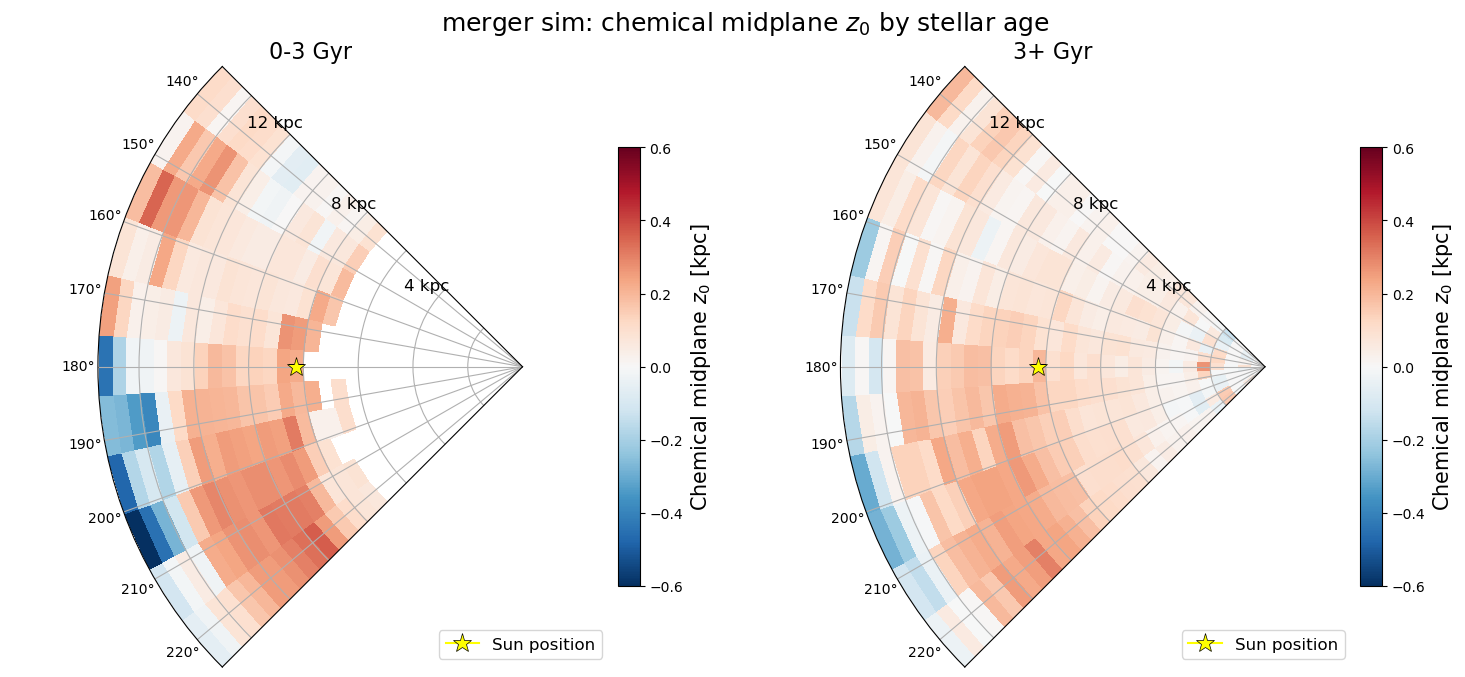

In [22]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

AGE_SPLIT   = 3.0                     # Gyr
SIMS_TO_RUN = ["merger"]              # add "host" to do both (each fit takes ~25 min per age bin)
FORCE_RERUN = False
AGE_BINS = {
    "young": ("0-3 Gyr", lambda a: a < AGE_SPLIT),
    "old":   ("3+ Gyr",  lambda a: a >= AGE_SPLIT),
}

# ---------------------------------------------------------------------------
# Fit each age bin (subset the stars first so each cell loop is faster)
# ---------------------------------------------------------------------------
z0_by_age = {}   # z0_by_age[sim][tag] = dict(z0_med=..., n_stars=..., ok_grid=...)

for name in SIMS_TO_RUN:
    d = prepared[name]
    z0_by_age[name] = {}
    for tag, (title, sel) in AGE_BINS.items():
        keep = sel(d["age"])
        path = f"2sim_grid_fit_z0_{name}_{tag}.pkl"

        if os.path.exists(path) and not FORCE_RERUN:
            saved = pickle.load(open(path, "rb"))
            print(f"{name} {title}: loaded {path}")
        else:
            seg_masks_fit = {i: d["segm"][i][keep] for i in d["SEG_PLOT_heat"]}
            mm.run_grid_fit(
                d["R"][keep], d["z"][keep], d["tracer"][keep], d["tracer_err"][keep],
                seg_masks_fit, R_edges,
                model_fn=mm.model_z0, label=f"{name}_{tag}_z0", results_path=path,
                minN_total=minN_seg_total, min_bin_count=min_bin_count,
                min_bins_for_fit=min_bins_for_fit, z_fit_min=z_fit_min, z_fit_max=z_fit_max,
            )
            saved = pickle.load(open(path, "rb"))

        z0_by_age[name][tag] = dict(z0_med=saved["z0_med"], ok_grid=saved["ok_grid"],
                                    n_stars_total=int(keep.sum()))
        print(f"{name} {title}: {int(keep.sum()):,} stars, "
              f"{int(saved['ok_grid'].sum())}/{saved['ok_grid'].size} cells fit")

# ---------------------------------------------------------------------------
# Heatmaps: young and old side by side, same color scale, no uncertainty panel
# ---------------------------------------------------------------------------
def plot_z0_heatmaps_by_age(sim_name, crowd_bounds, n_seg):
    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi
    assert len(theta_edges) - 1 == n_seg

    T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
    tmin, tmax = theta_edges[0], theta_edges[-1]
    theta_sun, R_sun = np.radians(180), 8.275

    fig = plt.figure(figsize=(15, 7))
    fig.suptitle(f"{sim_name} sim: chemical midplane $z_0$ by stellar age", fontsize=18)
    for k, tag in enumerate(AGE_BINS, start=1):
        title = AGE_BINS[tag][0]
        arr = np.ma.masked_invalid(z0_by_age[sim_name][tag]["z0_med"])
        ax = plt.subplot(1, 2, k, projection="polar")
        pcm = ax.pcolormesh(T_mesh, R_mesh, arr, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
        fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=15)
        ax.set_title(title, fontsize=16)
        ax.set_theta_zero_location("E"); ax.set_theta_direction(1)
        ax.set_rmax(R_edges[-1])
        ax.set_thetamin(np.degrees(tmin)); ax.set_thetamax(np.degrees(tmax))
        ax.set_yticklabels([])
        for r in R_edges[R_edges % 4 == 0]:
            ax.text(tmin - np.radians(3), r, f"{r:.0f} kpc", fontsize=12, ha="right", va="center")
        ax.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
                markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun position")
        ax.legend(loc="lower right", fontsize=12)
    plt.tight_layout()
    plt.show()

for name in SIMS_TO_RUN:
    d = prepared[name]
    plot_z0_heatmaps_by_age(name, d["crowd_bounds"], len(d["SEG_PLOT_heat"]))

host: 330 cells with median, 330 with an interior n(z) peak
merger: 330 cells with median, 330 with an interior n(z) peak


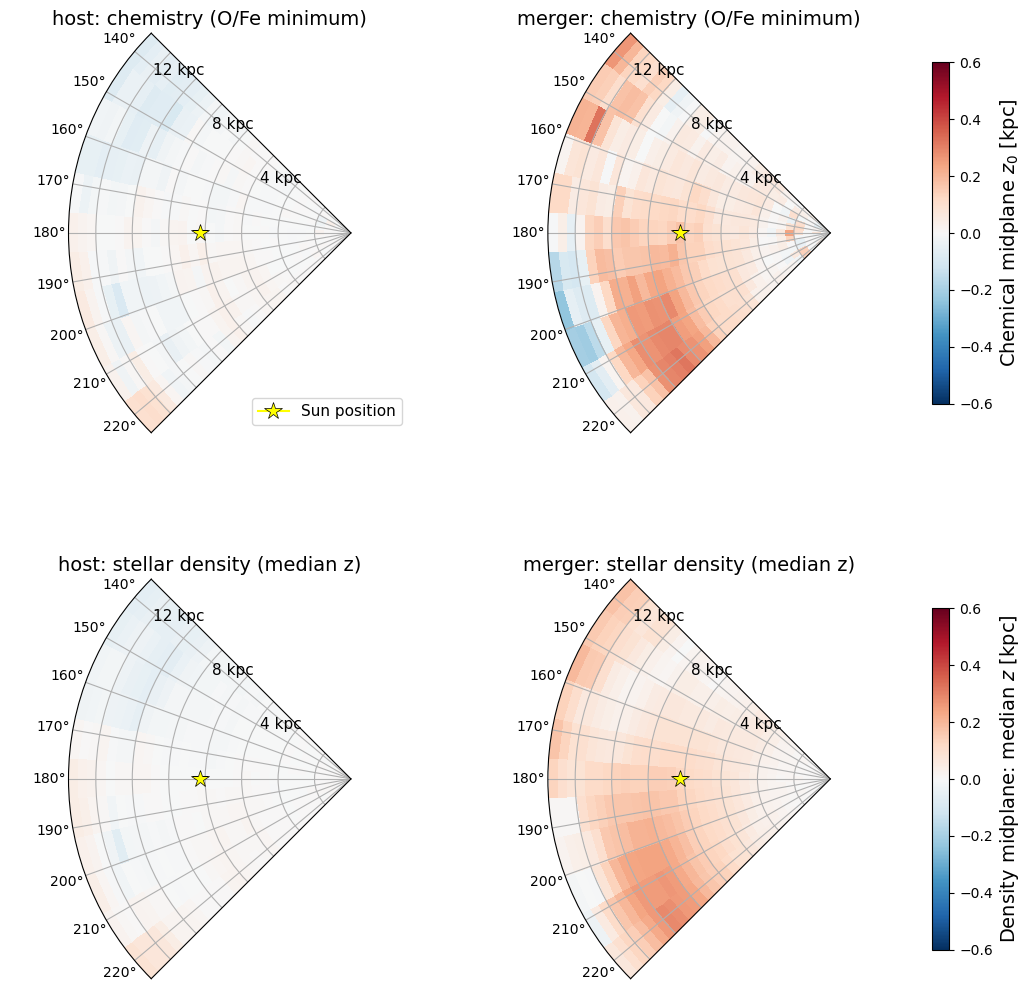

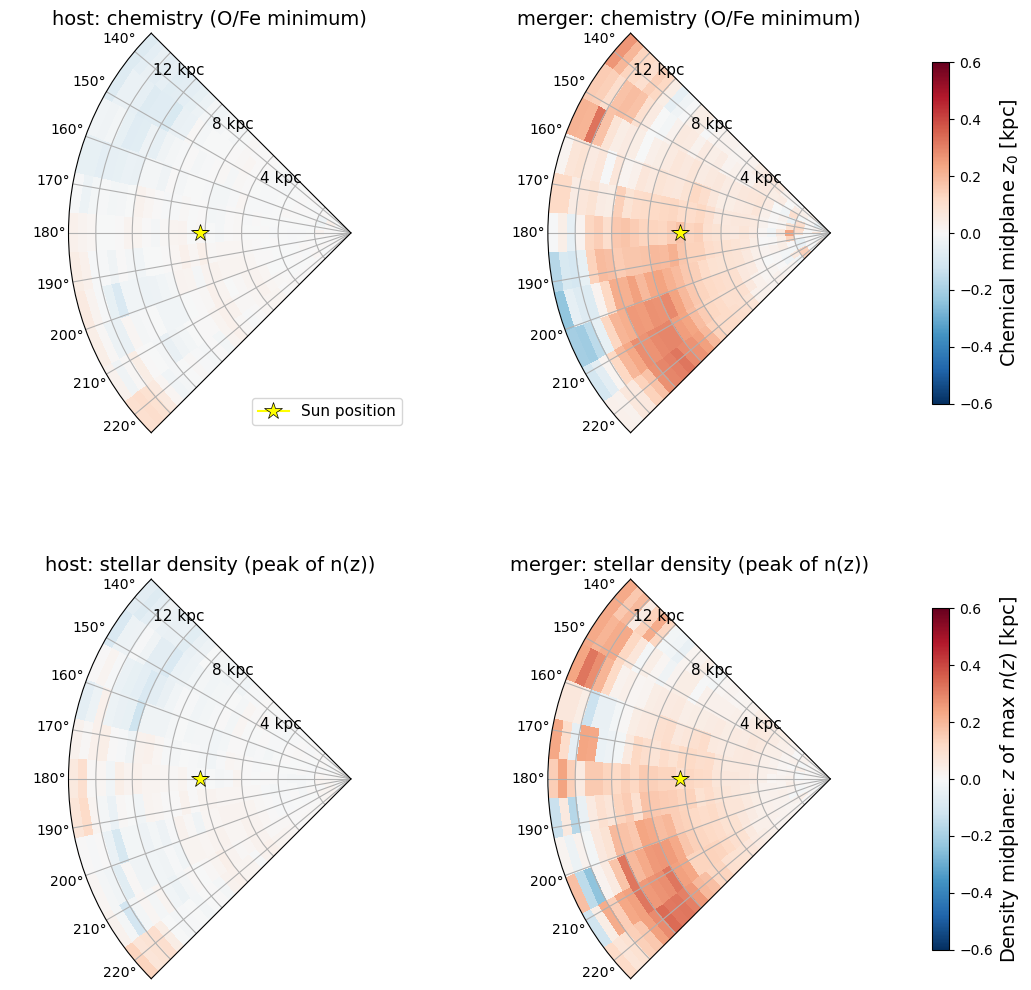

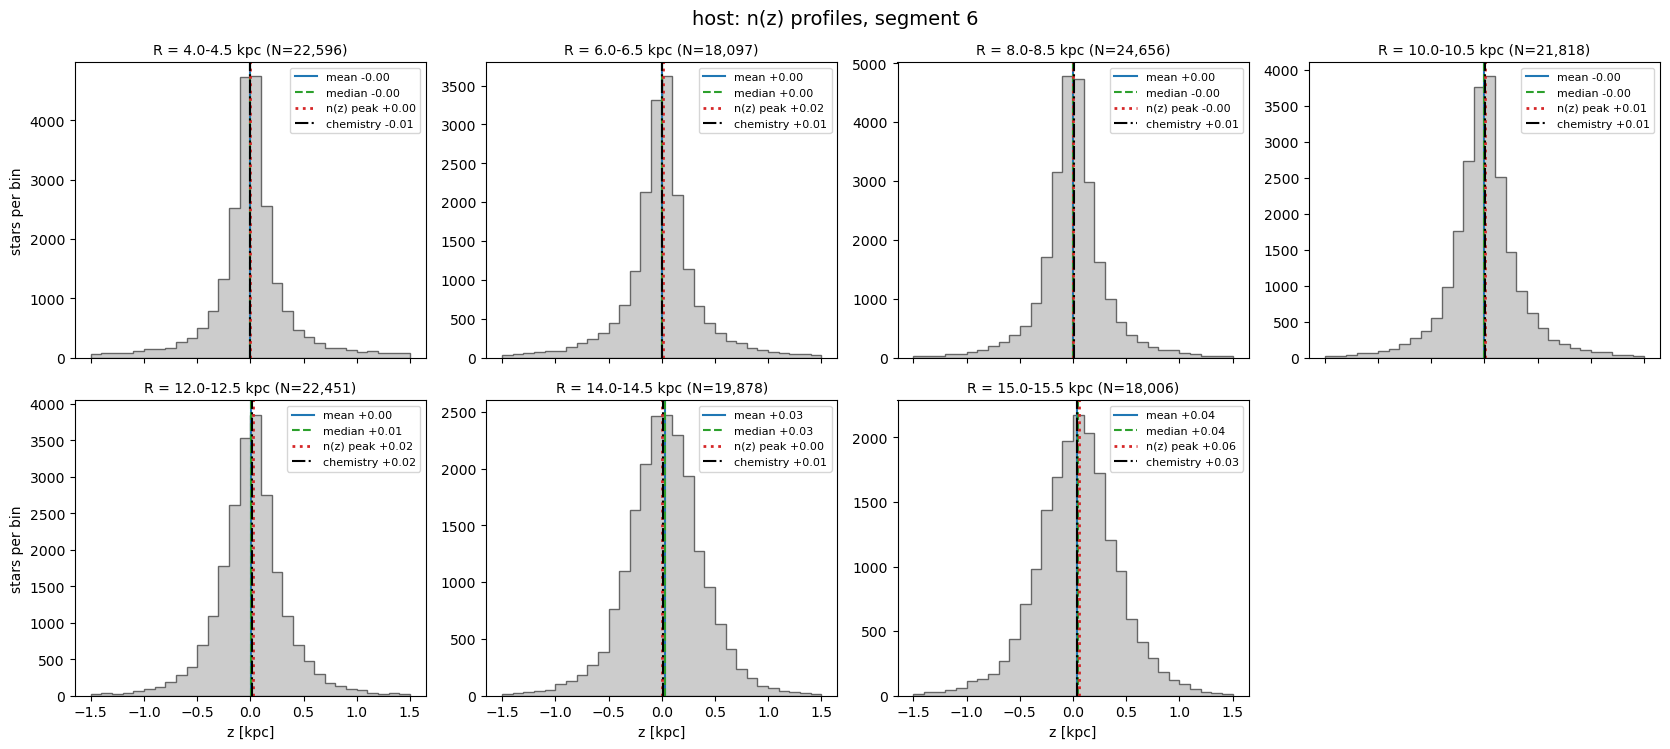

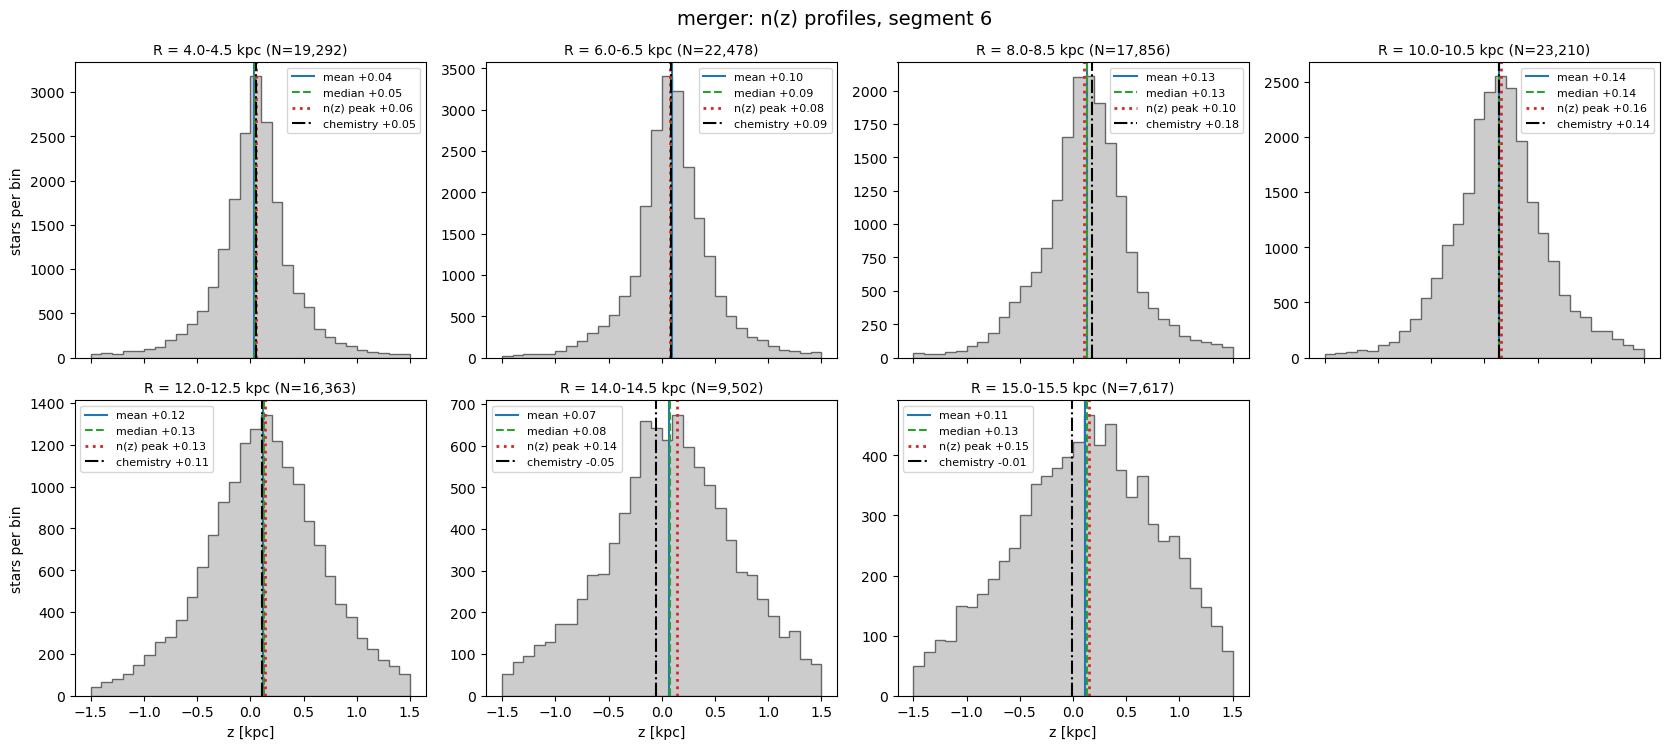

In [19]:
import numpy as np
import matplotlib.pyplot as plt

Z_PROFILE_BIN = 0.1                                   # kpc, bin width for n(z)
z_prof_edges = np.arange(z_fit_min, z_fit_max + 1e-9, Z_PROFILE_BIN)
n_zb = len(z_prof_edges) - 1

def _cell_index(d):
    n_R = len(R_edges) - 1
    iR = np.digitize(d["R"], R_edges) - 1
    ok = (iR >= 0) & (iR < n_R) & (d["z"] >= z_fit_min) & (d["z"] <= z_fit_max)
    return iR, ok

# ---------------------------------------------------------------------------
# Median z, and z of peak number density, per (R bin, segment) cell
# ---------------------------------------------------------------------------
def density_midplane_grids(d, minN=minN_seg_total):
    n_R, n_seg = len(R_edges) - 1, len(d["SEG_PLOT_heat"])
    iR, in_win = _cell_index(d)
    iz = np.clip(np.digitize(d["z"], z_prof_edges) - 1, 0, n_zb - 1)

    med = np.full((n_R, n_seg), np.nan)
    peak = np.full((n_R, n_seg), np.nan)
    z_ctr = 0.5 * (z_prof_edges[1:] + z_prof_edges[:-1])

    for j, seg in enumerate(d["SEG_PLOT_heat"]):
        m = in_win & d["segm"][seg]
        iRs, zs, izs = iR[m], d["z"][m], iz[m]

        # --- median: sort stars by R bin once, then take the median of each chunk
        order = np.argsort(iRs, kind="stable")
        iRs_sorted, zs_sorted = iRs[order], zs[order]
        bounds = np.searchsorted(iRs_sorted, np.arange(n_R + 1))
        for k in range(n_R):
            chunk = zs_sorted[bounds[k]:bounds[k + 1]]
            if chunk.size >= minN:
                med[k, j] = np.median(chunk)

        # --- peak of n(z): 2D histogram (R bin x z bin), parabola refinement
        counts = np.bincount(iRs * n_zb + izs, minlength=n_R * n_zb).reshape(n_R, n_zb)
        for k in range(n_R):
            c = counts[k]
            if c.sum() < minN:
                continue
            p = int(np.argmax(c))
            if p == 0 or p == n_zb - 1:
                continue                     # no interior maximum in the window
            denom = c[p - 1] - 2 * c[p] + c[p + 1]
            delta = 0.5 * (c[p - 1] - c[p + 1]) / denom if denom != 0 else 0.0
            peak[k, j] = z_ctr[p] + np.clip(delta, -0.5, 0.5) * Z_PROFILE_BIN
    return med, peak

dens = {}
for name in ["host", "merger"]:
    med, peak = density_midplane_grids(prepared[name])
    dens[name] = dict(median=med, peak=peak)
    print(f"{name}: {int(np.isfinite(med).sum())} cells with median, "
          f"{int(np.isfinite(peak).sum())} with an interior n(z) peak")

# ---------------------------------------------------------------------------
# 2x2 figure: chemistry (top) vs a density estimate (bottom), one colorbar per row
# ---------------------------------------------------------------------------
def plot_chem_vs_density(method_key, method_title, cbar_label):
    d0 = prepared["host"]
    te = np.unwrap(np.array(d0["crowd_bounds"], float))
    for i in range(1, len(te)):
        while te[i] <= te[i - 1]:
            te[i] += 2 * np.pi
    T_mesh, R_mesh = np.meshgrid(te, R_edges)
    tmin, tmax = te[0], te[-1]
    theta_sun, R_sun = np.radians(180), 8.275

    rows = [
        ("chemistry (O/Fe minimum)", {n: z0_summary[n]["z0_med"] for n in ["host", "merger"]},
         r"Chemical midplane $z_0$ [kpc]"),
        (method_title, {n: dens[n][method_key] for n in ["host", "merger"]}, cbar_label),
    ]
    fig, axes = plt.subplots(2, 2, subplot_kw={"projection": "polar"}, figsize=(14, 13))
    for i, (row_title, grids, lab) in enumerate(rows):
        for j, name in enumerate(["host", "merger"]):
            ax = axes[i, j]
            pcm = ax.pcolormesh(T_mesh, R_mesh, np.ma.masked_invalid(grids[name]),
                                cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
            ax.set_title(f"{name}: {row_title}", fontsize=14)
            ax.set_theta_zero_location("E"); ax.set_theta_direction(1)
            ax.set_rmax(R_edges[-1])
            ax.set_thetamin(np.degrees(tmin)); ax.set_thetamax(np.degrees(tmax))
            ax.set_yticklabels([])
            for r in R_edges[R_edges % 4 == 0]:
                ax.text(tmin - np.radians(3), r, f"{r:.0f} kpc", fontsize=11, ha="right", va="center")
            ax.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=13,
                    markeredgecolor="k", markeredgewidth=0.5, zorder=5,
                    label="Sun position" if (i == 0 and j == 0) else None)
        cb = fig.colorbar(pcm, ax=axes[i, :].tolist(), pad=0.04, shrink=0.75, location="right")
        cb.set_label(lab, fontsize=14)
    axes[0, 0].legend(loc="lower right", fontsize=11)
    plt.show()

plot_chem_vs_density("median", "stellar density (median z)", r"Density midplane: median $z$ [kpc]")
plot_chem_vs_density("peak", "stellar density (peak of n(z))", r"Density midplane: $z$ of max $n(z)$ [kpc]")

# ---------------------------------------------------------------------------
# Example vertical density profiles n(z), with every midplane estimate marked
# ---------------------------------------------------------------------------
def plot_nz_profiles(R_show=(4, 6, 8, 10, 12, 14, 16), j_seg=5, n_cols=4):
    n_R_bins = len(R_edges) - 1
    n_rows = int(np.ceil(len(R_show) / n_cols))
    for name in ["host", "merger"]:
        d = prepared[name]
        iR, in_win = _cell_index(d)
        seg = d["SEG_PLOT_heat"][j_seg]

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.8 * n_rows),
                                 sharex=True, squeeze=False)
        fig.suptitle(f"{name}: n(z) profiles, segment {j_seg + 1}", fontsize=14)
        for ax in axes.ravel():
            ax.set_visible(False)

        for idx, Rt in enumerate(R_show):
            ax = axes.ravel()[idx]
            ax.set_visible(True)
            k = int(np.clip(np.searchsorted(R_edges, Rt, side="right") - 1, 0, n_R_bins - 1))
            m = in_win & d["segm"][seg] & (iR == k)
            z = d["z"][m]
            title = f"R = {R_edges[k]:.1f}-{R_edges[k + 1]:.1f} kpc"
            if z.size < minN_seg_total:
                ax.set_title(f"{title}: too few stars", fontsize=10)
                continue
            ax.hist(z, bins=z_prof_edges, histtype="stepfilled", color="0.8", edgecolor="0.4")
            ax.axvline(np.mean(z), color="C0", ls="-", label=f"mean {np.mean(z):+.2f}")
            ax.axvline(np.median(z), color="C2", ls="--", label=f"median {np.median(z):+.2f}")
            pk = dens[name]["peak"][k, j_seg]
            if np.isfinite(pk):
                ax.axvline(pk, color="C3", ls=":", lw=2, label=f"n(z) peak {pk:+.2f}")
            zc = z0_summary[name]["z0_med"][k, j_seg]
            if np.isfinite(zc):
                ax.axvline(zc, color="k", ls="-.", label=f"chemistry {zc:+.2f}")
            ax.set_title(f"{title} (N={z.size:,})", fontsize=10)
            ax.legend(fontsize=8)
            if idx // n_cols == n_rows - 1:
                ax.set_xlabel("z [kpc]")
            if idx % n_cols == 0:
                ax.set_ylabel("stars per bin")
        plt.tight_layout()
        plt.show()

plot_nz_profiles()

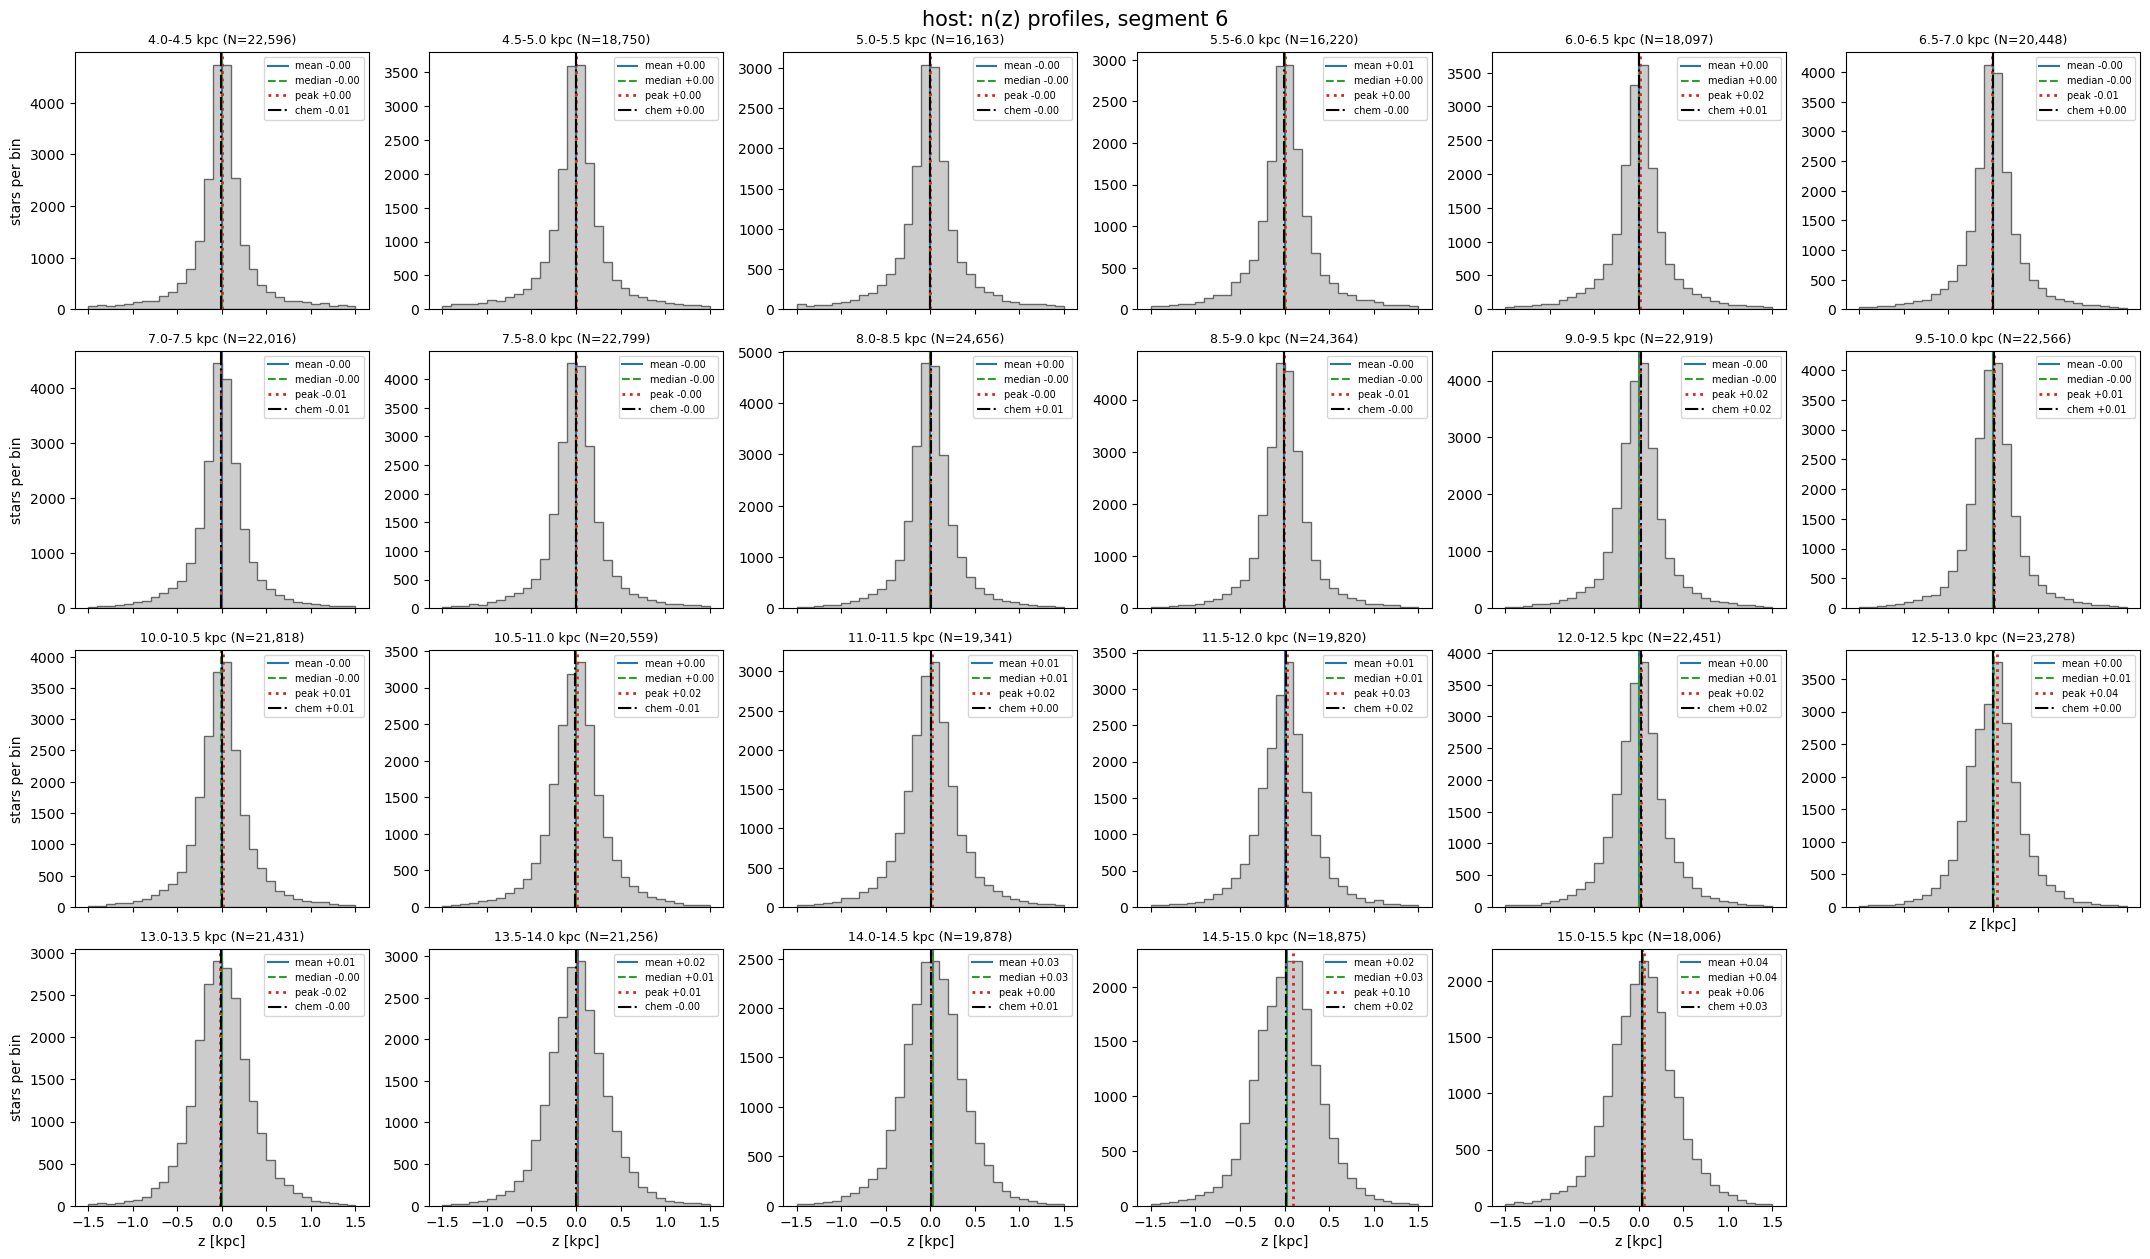

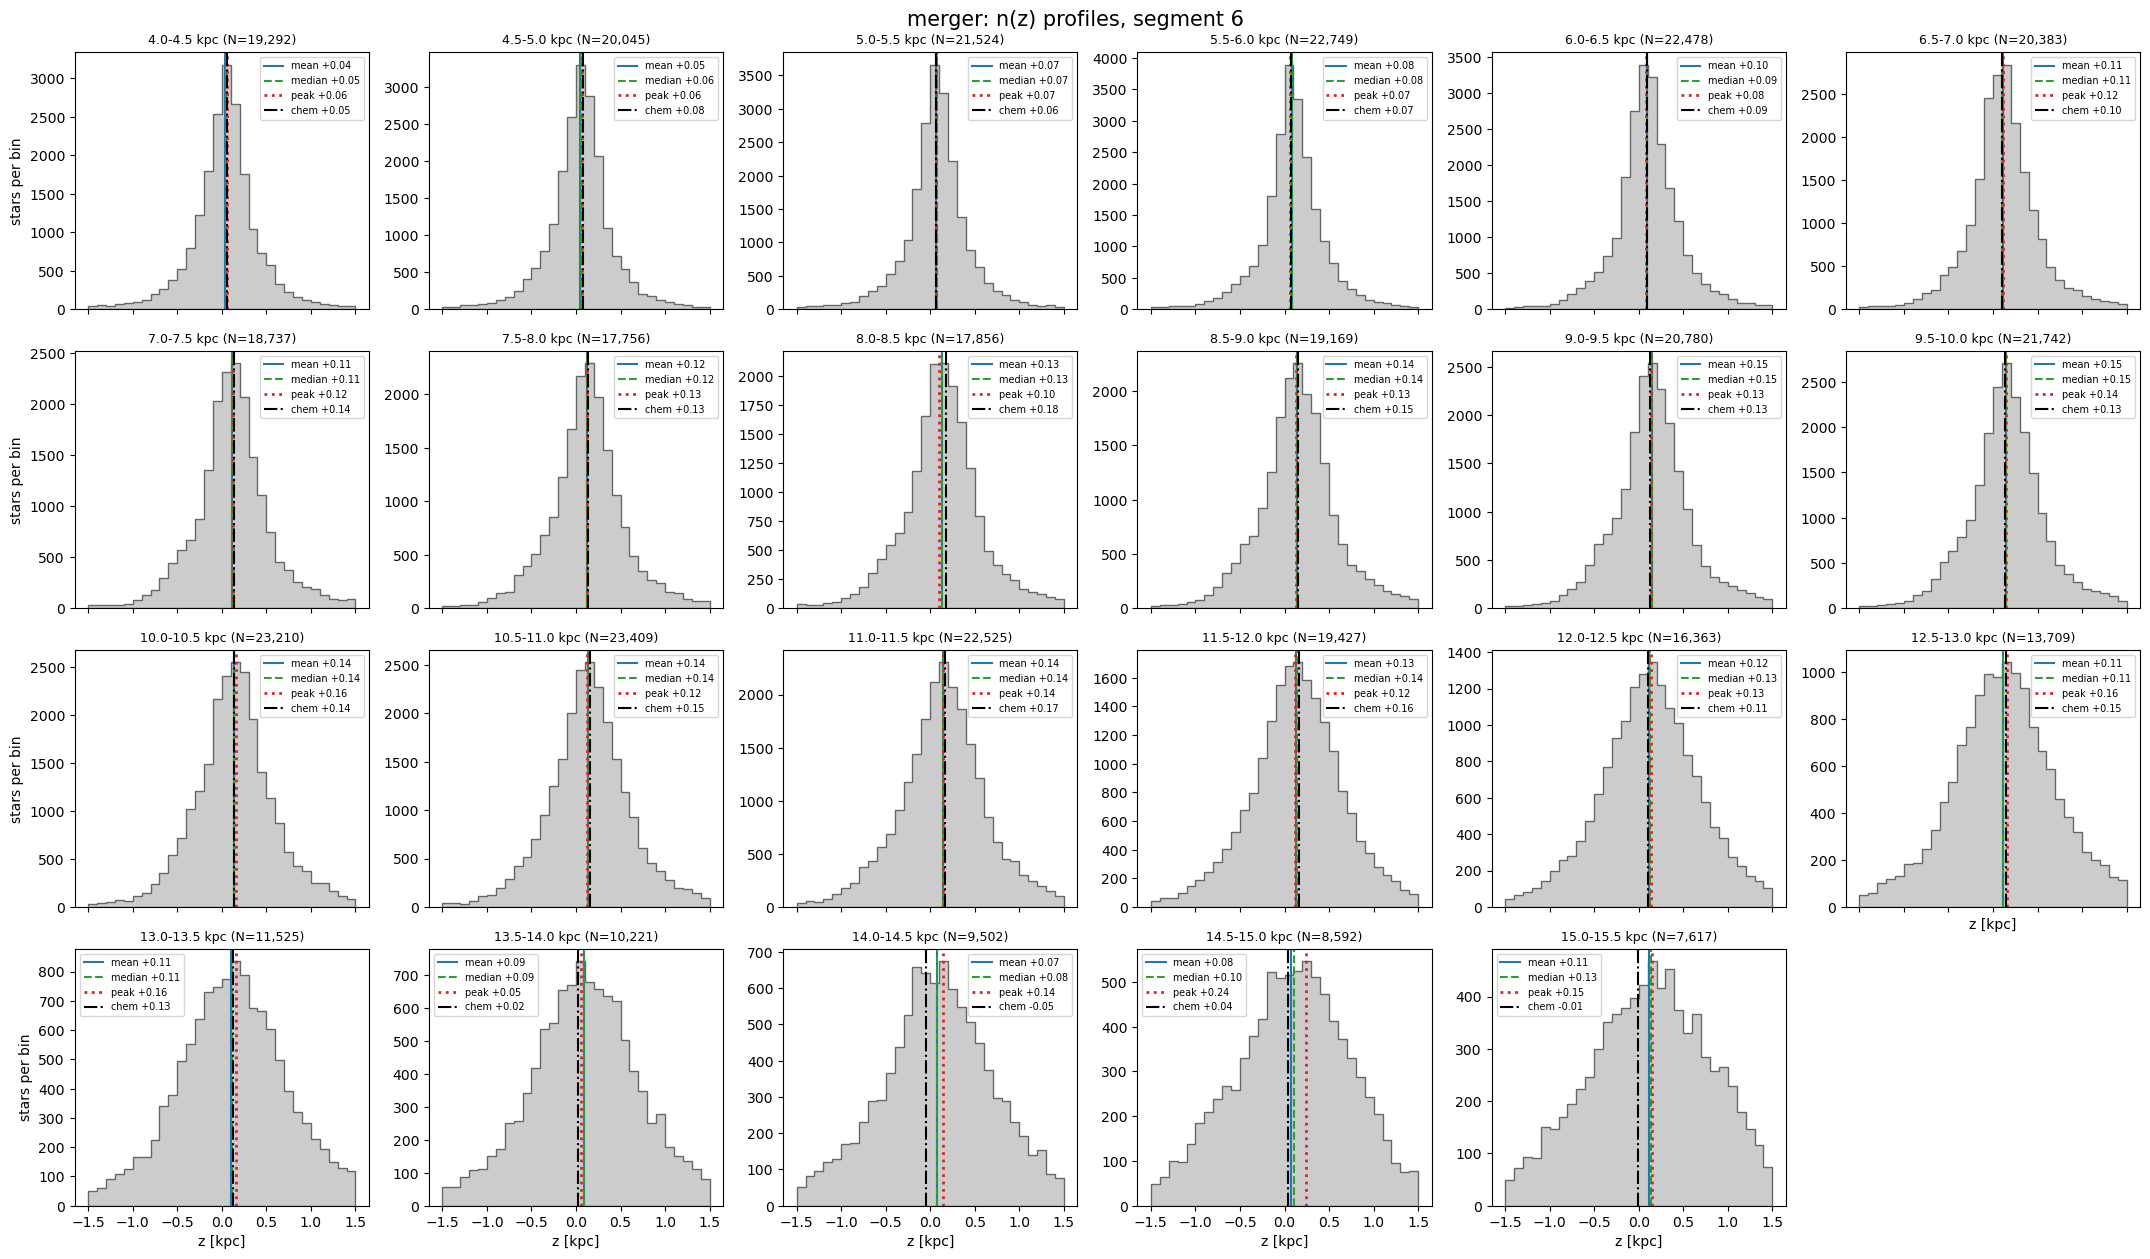

In [21]:
def plot_nz_profiles(R_lo=4.0, R_hi=16.0, j_seg=5, n_cols=6):
    bin_ids = [k for k in range(len(R_edges) - 1)
               if R_edges[k] >= R_lo - 1e-9 and R_edges[k + 1] <= R_hi + 1e-9]
    n_rows = int(np.ceil(len(bin_ids) / n_cols))

    for name in ["host", "merger"]:
        d = prepared[name]
        iR, in_win = _cell_index(d)
        seg = d["SEG_PLOT_heat"][j_seg]

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6 * n_cols, 3.2 * n_rows),
                                 sharex=True, squeeze=False)
        fig.suptitle(f"{name}: n(z) profiles, segment {j_seg + 1}", fontsize=15)
        for ax in axes.ravel():
            ax.set_visible(False)

        for idx, k in enumerate(bin_ids):
            ax = axes.ravel()[idx]
            ax.set_visible(True)
            m = in_win & d["segm"][seg] & (iR == k)
            z = d["z"][m]
            title = f"{R_edges[k]:.1f}-{R_edges[k + 1]:.1f} kpc"
            if z.size < minN_seg_total:
                ax.set_title(f"{title}: N={z.size}, too few", fontsize=9)
            else:
                ax.hist(z, bins=z_prof_edges, histtype="stepfilled", color="0.8", edgecolor="0.4")
                ax.axvline(np.mean(z), color="C0", ls="-", label=f"mean {np.mean(z):+.2f}")
                ax.axvline(np.median(z), color="C2", ls="--", label=f"median {np.median(z):+.2f}")
                pk = dens[name]["peak"][k, j_seg]
                if np.isfinite(pk):
                    ax.axvline(pk, color="C3", ls=":", lw=2, label=f"peak {pk:+.2f}")
                zc = z0_summary[name]["z0_med"][k, j_seg]
                if np.isfinite(zc):
                    ax.axvline(zc, color="k", ls="-.", label=f"chem {zc:+.2f}")
                ax.set_title(f"{title} (N={z.size:,})", fontsize=9)
                ax.legend(fontsize=7)
            if idx // n_cols == n_rows - 1 or idx + n_cols >= len(bin_ids):
                ax.set_xlabel("z [kpc]")
            if idx % n_cols == 0:
                ax.set_ylabel("stars per bin")
        plt.tight_layout()
        plt.show()

plot_nz_profiles()